# Irony Detection in Tweets — Machine Learning Mini-Project

**Dataset:** TweetEval – Irony (binary classification: `1` = irony, `0` = non_irony)
**Group:** Chaker Iben Hadj Amor, Sabrine Zouaoui, Roeya Sliti, Manar Mrabet

## Part A: Exploratory Data Analysis (EDA) and Text Preprocessing

In this notebook we:
1. explore the data (columns, classes, text length, plots);
2. clean the tweets and create the `text_clean` column used by the models.

## 0. Setup

In [1]:
import sys
sys.path.append("..")   # lets us import the shared code from the src/ folder

import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

from src.config import RANDOM_STATE, LABEL_NAMES, PROCESSED_DIR   # shared settings
from src.data import load_split, drop_corrupted_rows              # data loading
from src.cleaning import clean_text, STOPS_ALL, STOPS_KEEP_NEG    # text cleaning

sns.set_theme(style="whitegrid")   # plot style: white background with a grid

# 1. Exploratory Data Analysis (EDA)

## 1.1 Loading the data
Text and labels are stored in separate files (one tweet per line), so `load_split` reads both and builds a DataFrame with the columns `text` and `label`.

In [2]:
# Load the three official splits
train = load_split("train")
val = load_split("val")
test = load_split("test")

# Show (number of rows, number of columns) of each split
print("train :", train.shape)
print("val   :", val.shape)
print("test  :", test.shape)

train : (2862, 2)
val   : (955, 2)
test  : (784, 2)


The train split contains 3 corrupted rows: several tweets were merged on the same line, separated by tab characters.
We remove them from the train split only (validation and test are not modified).

In [3]:
# Count the corrupted rows (they contain a tab character)
print("Corrupted rows in train:", train["text"].str.contains("\t").sum())

# Remove them and check the new size (2862 - 3 = 2859)
train = drop_corrupted_rows(train)
print("train :", train.shape)
assert len(train) == 2859

Corrupted rows in train: 3
train : (2859, 2)


## 1.2 Available columns

In [4]:
# First 10 rows
train.head(10)

,text,label
0,seeing ppl walking w/ crutches makes me really...,1
1,"look for the girl with the broken smile, ask h...",0
2,Now I remember why I buy books online @user #s...,1
3,@user @user So is he banded from wearing the c...,1
4,Just found out there are Etch A Sketch apps. ...,1
5,"Hey what do you know, one of the witnesses sup...",1
6,@user on stage at #flzjingleball at the @user ...,0
7,You know it's going to be a great day when you...,1
8,Halfway thorough my workday ... Woooo,1
9,Would like to thank my nephew for giving me hi...,1


In [5]:
# Column names, types and number of non-empty values
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2859 entries, 0 to 2858
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    2859 non-null   str  
 1   label   2859 non-null   int64
dtypes: int64(1), str(1)
memory usage: 44.8 KB


In [6]:
# Basic statistics of the numeric columns (only label for now)
train.describe()

,label
count,2859.000000
mean,0.505421
std,0.500058
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


The DataFrame has two columns: `text` (the tweet) and `label` (0 = non_irony, 1 = irony), with no missing values.
The mean of `label` is close to 0.5, so the two classes are almost balanced in the train split.

## 1.3 Class distribution

In [7]:
# Number and percentage of tweets per class, for each split
for name, df in [("train", train), ("val", val), ("test", test)]:
    print(name)
    print(df["label"].value_counts().sort_index())
    print(df["label"].value_counts(normalize=True).sort_index().round(3) * 100)
    print()

train
label
0    1414
1    1445
Name: count, dtype: int64
label
0    49.5
1    50.5
Name: proportion, dtype: float64

val
label
0    499
1    456
Name: count, dtype: int64
label
0    52.3
1    47.7
Name: proportion, dtype: float64

test
label
0    473
1    311
Name: count, dtype: int64
label
0    60.3
1    39.7
Name: proportion, dtype: float64



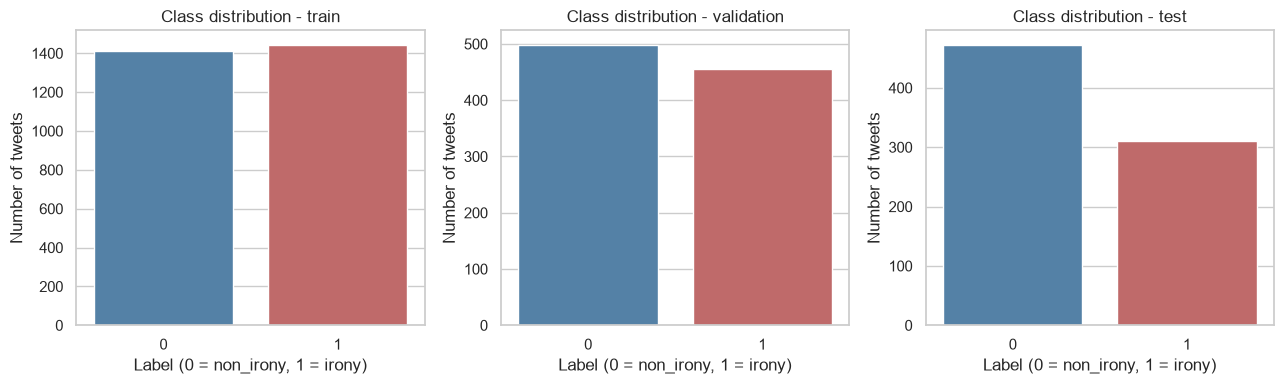

In [8]:
# Bar plot of the class distribution (one plot per split)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, name, df in zip(axes, ["train", "validation", "test"], [train, val, test]):
    sns.countplot(x="label", hue="label", data=df, ax=ax, palette=["steelblue", "indianred"], legend=False)
    ax.set_title("Class distribution - " + name)
    ax.set_xlabel("Label (0 = non_irony, 1 = irony)")
    ax.set_ylabel("Number of tweets")

plt.tight_layout()
plt.show()

The train split (1414 non_irony / 1445 irony) and the validation split (499 / 456) are almost balanced.
The test split is not: 473 non-ironic tweets against 311 ironic ones (about 60% / 40%).
For this reason we will not rely on accuracy alone: we will mainly use the macro F1-score, which gives the same weight to both classes.

## 1.4 Text length

In [9]:
# Add two columns: number of characters and number of words of each tweet
train["n_chars"] = train["text"].str.len()
train["n_words"] = train["text"].str.split().str.len()

train[["n_chars", "n_words"]].describe()

,n_chars,n_words
count,2859.000000,2859.000000
mean,78.780693,13.521861
std,32.416796,5.871894
min,6.000000,1.000000
25%,52.000000,9.000000
50%,78.000000,13.000000
75%,106.000000,18.000000
max,141.000000,33.000000


In [10]:
# Average length of each class
train.groupby("label")[["n_chars", "n_words"]].mean().round(1)

,n_chars,n_words
label,,
0,79.3,13.5
1,78.2,13.5


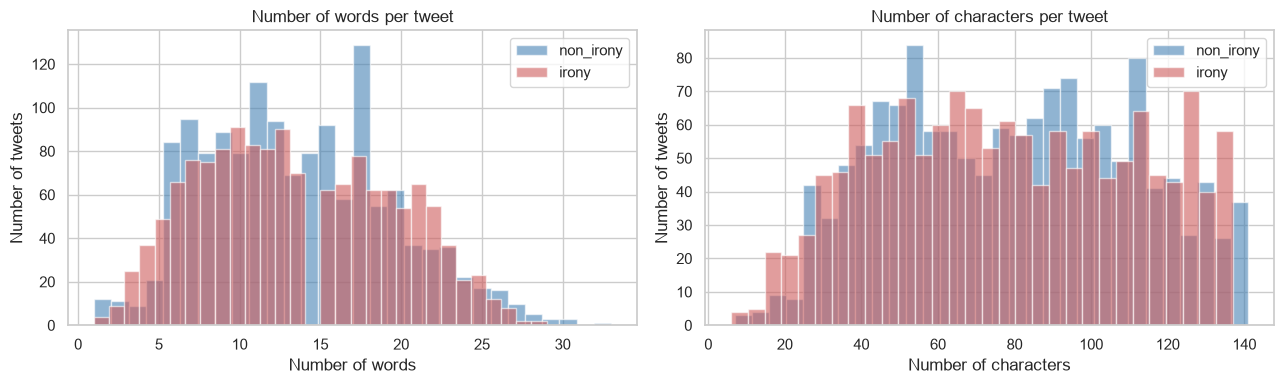

In [11]:
# Histograms of the length (words and characters), one color per class
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for col, ax, unit in zip(["n_words", "n_chars"], axes, ["words", "characters"]):
    ax.hist(train[train["label"] == 0][col], bins=30, alpha=0.6, label=LABEL_NAMES[0], color="steelblue")
    ax.hist(train[train["label"] == 1][col], bins=30, alpha=0.6, label=LABEL_NAMES[1], color="indianred")
    ax.set_title("Number of " + unit + " per tweet")
    ax.set_xlabel("Number of " + unit)
    ax.set_ylabel("Number of tweets")
    ax.legend()

plt.tight_layout()
plt.show()

A tweet has 13 to 14 words on average (about 79 characters), with a maximum of 33 words and 141 characters once the corrupted rows are removed.
Both classes have almost the same length (13.5 words on average in each class), so the length alone does not help to detect irony.

## 1.5 WordClouds: most frequent words per class

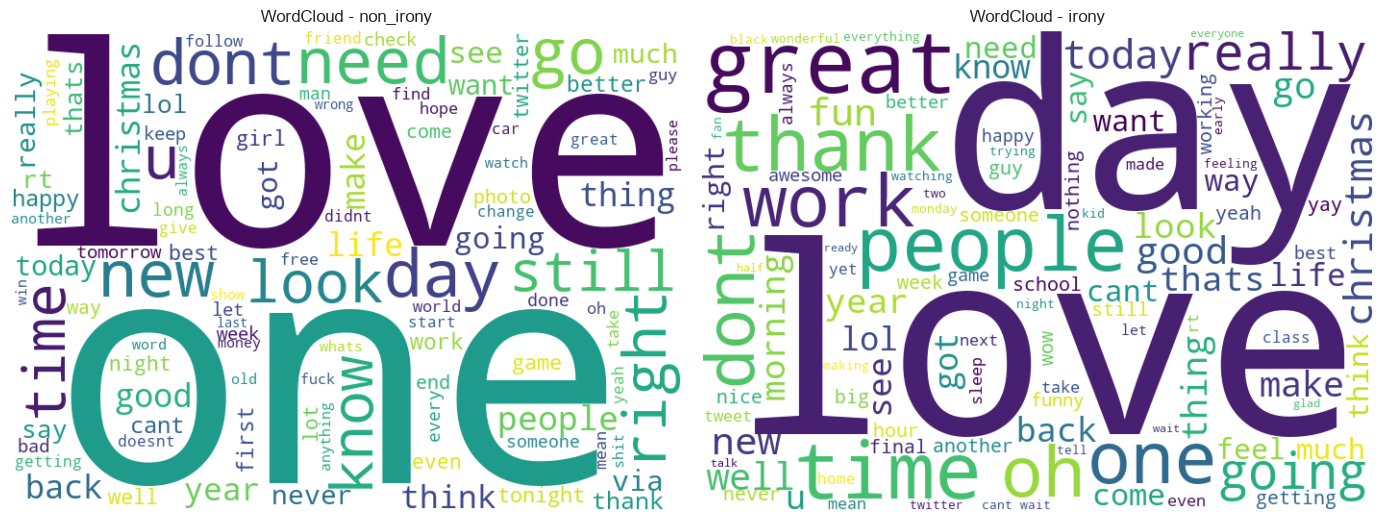

In [12]:
# Words ignored in the clouds: English stopwords + a few useless tokens
ignored_words = set(STOPWORDS) | {"user", "http", "https", "co", "amp"}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, lab in zip(axes, [0, 1]):
    # Remove links and mentions (default clean_text), then join all tweets of the class into one text
    texts = train[train["label"] == lab]["text"].apply(clean_text)
    cloud = WordCloud(width=700, height=500, background_color="white", stopwords=ignored_words,
                      max_words=100, random_state=RANDOM_STATE).generate(" ".join(texts))
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title("WordCloud - " + LABEL_NAMES[lab])
    ax.axis("off")

plt.tight_layout()
plt.show()

The two clouds are different. In the irony class we mostly see positive words (*love*, *great*, *fun*, *thank*, *nice*, *awesome*, *wow*, *yay*).
In the non_irony class the dominant words are more neutral (*will*, *one*, *new*, *think*, *need*).
Positive words are therefore more frequent in ironic tweets, which explains why irony is hard to detect: the same words are also used sincerely.

# 2. Text Preprocessing

## 2.1 What the tweets contain

In [13]:
# 8 random tweets (fixed seed so we always see the same ones)
pd.set_option("display.max_colwidth", 200)
train[["text", "label"]].sample(8, random_state=RANDOM_STATE)

,text,label
1584,@user doesn't lucky and fortunate mean the same thing?,1
1746,Drinking an Imperial IPA (2014-) by @user - #photo,0
772,I love being on hold. Especially when the music is so great.,1
1729,Look! It's a white Christmas after all! #MinnesotaProblems,1
387,#almajmoua participating in the 4th #CSR forum #lebanon #togetherwegrow -for-profit #microfinance #supporting...,0
407,#UKPLUS= Consists of Free Lebara2Lebara 3000MINs and 3000SMS UNLIMITED. #NO UNLIMITED SMS TO OTHER NETWORK Only consists of 1000SMS,0
2441,"@user oh brother, the bar for journalism is very high these days @user why do you follow such retards?",1
1992,Ariana Grandes makeup is always sooo flawless 🙊,0


In [14]:
# How many tweets contain mentions, links and hashtags?
print("Tweets with a mention (@user):", train["text"].str.contains("@").sum())
print("Tweets with a link (http)    :", train["text"].str.contains("http").sum())
print("Tweets with a hashtag (#)    :", train["text"].str.contains("#").sum())
print("Total number of tweets       :", len(train))

Tweets with a mention (@user): 1164
Tweets with a link (http)    : 23
Tweets with a hashtag (#)    : 1101
Total number of tweets       : 2859


Mentions are already anonymised as `@user`. Many tweets contain a mention or a hashtag, very few contain a link.

Another check: `#not`, `#irony` and `#sarcasm` are the hashtags that were used to collect the ironic tweets.

In [15]:
# True if the tweet contains one of the three collection hashtags (exact match, so #notsarcasm does not count)
def has_irony_hashtag(text):
    hashtags = re.findall(r"#\w+", text.lower())
    return any(h in hashtags for h in ["#not", "#irony", "#sarcasm"])

# Count these tweets in each split
for name, df in [("train", train), ("val", val), ("test", test)]:
    print(name, ":", df["text"].apply(has_irony_hashtag).sum(), "tweets out of", len(df))

# Share of ironic tweets among the test tweets that contain them
in_test = test[test["text"].apply(has_irony_hashtag)]
print("Share of irony tweets among them (test):", round(in_test["label"].mean(), 2))

train : 0 tweets out of 2859
val : 0 tweets out of 955
test : 431 tweets out of 784
Share of irony tweets among them (test): 0.72


No tweet of the train or validation split contains these hashtags (they were removed from the training data), but 431 of the 784 test tweets do, and 72% of them are ironic.
The test split was therefore not prepared like the train and validation splits: the models never see these hashtags during training.
We do not modify the test split, but we must keep this in mind when we interpret the final score. All our choices (cleaning, models) are made on the validation split only.

## 2.2 Our cleaning choices

In [16]:
# Does the NLTK stopword list contain negations?
for word in ["not", "no", "nor", "don't", "isn't", "never"]:
    print(word, "->", word in STOPS_ALL)

print()
print("NLTK stopwords               :", len(STOPS_ALL))
print("Stopwords without negations  :", len(STOPS_KEEP_NEG))

not -> True
no -> True
nor -> True
don't -> True
isn't -> True
never -> False

NLTK stopwords               : 198
Stopwords without negations  : 158


The NLTK stopword list contains negations (`not`, `no`, `don't`...). Removing them changes the meaning of a tweet ("not good" becomes "good"),
so we use a stopword list **without the negations**.

Some steps (lowercasing, removing punctuation such as `!!!` or `...`, removing stopwords) may also remove irony signals.
Instead of guessing, we test 5 versions of the cleaning, each one adding a step to the previous one.
Each version is vectorized with TF-IDF, a logistic regression is trained on the **train** split, and the macro F1-score is measured on the **validation** split (never on the test split).
The vectorizer keeps punctuation and emojis as tokens, otherwise we could not measure the effect of punctuation.

In [17]:
# The 5 cleaning versions (each one adds a step to the previous one)
v1 = dict(remove_links=True, remove_mentions=True, hashtags="keep", lowercase=False,
          remove_stopwords=False, remove_punct=False, lemmatize=False)   # same as the defaults of clean_text
v2 = dict(v1, hashtags="strip_symbol", lowercase=True)   # + lowercase and remove the # sign
v3 = dict(v2, remove_stopwords=True)                     # + remove stopwords (negations kept)
v4 = dict(v3, remove_punct=True)                         # + remove punctuation
v5 = dict(v4, lemmatize=True)                            # + lemmatization

versions = {
    "V1 links and mentions removed": v1,
    "V2 + lowercase, # removed": v2,
    "V3 + stopwords (negations kept)": v3,
    "V4 + punctuation removed": v4,
    "V5 + lemmatization": v5,
}

In [18]:
# Train a simple model for one cleaning version and score it on the validation split
def test_version(params):
    X_train = train["text"].apply(lambda t: clean_text(t, **params))   # clean train
    X_val = val["text"].apply(lambda t: clean_text(t, **params))       # clean validation the same way

    model = Pipeline([
        ("tfidf", TfidfVectorizer(token_pattern=r"[\w']+|[^\w\s]", lowercase=False)),  # words + punctuation/emojis
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])
    model.fit(X_train, train["label"])    # learn on train only
    pred = model.predict(X_val)           # predict on validation

    return {"accuracy": accuracy_score(val["label"], pred),
            "f1_macro": f1_score(val["label"], pred, average="macro")}

# One row per cleaning version
results = pd.DataFrame({name: test_version(params) for name, params in versions.items()}).T.round(4)
results

,accuracy,f1_macro
V1 links and mentions removed,0.6314,0.6312
"V2 + lowercase, # removed",0.6178,0.6178
V3 + stopwords (negations kept),0.6251,0.6247
V4 + punctuation removed,0.6241,0.6234
V5 + lemmatization,0.6147,0.6144


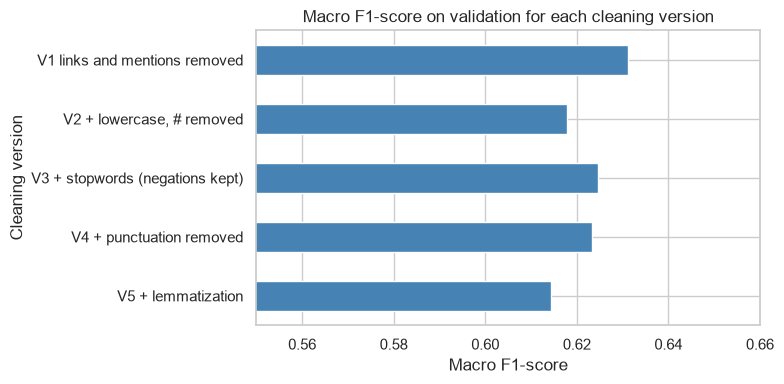

In [19]:
# Bar plot of the macro F1-score of each version
plt.figure(figsize=(8, 4))
results["f1_macro"].iloc[::-1].plot(kind="barh", color="steelblue")
plt.title("Macro F1-score on validation for each cleaning version")
plt.xlabel("Macro F1-score")
plt.ylabel("Cleaning version")
plt.xlim(0.55, 0.66)
plt.tight_layout()
plt.show()

Version V1 (only links and mentions removed) gets the best macro F1-score on the validation split (0.631).
Lowercasing and removing the `#` sign (V2) lowers the score (0.618), and the next steps (stopwords, punctuation, lemmatization) do not improve it: the scores stay between 0.614 and 0.625.
The differences are small (the validation split has only 955 tweets, so part of them may be due to chance), but no cleaning step shows a real gain.

**Chosen version:** V1. Links and mentions are noise without information, and we keep everything else (capital letters, punctuation such as `!!!` or `...`, hashtag words, emojis, negations)
because these elements may carry the tone of an ironic tweet and the experiment does not show that removing them helps.

## 2.3 Creating the `text_clean` column

In [20]:
# Pick the version with the best macro F1-score on validation
best = results["f1_macro"].idxmax()
final_config = versions[best]

print("Chosen version:", best)
print(final_config)

Chosen version: V1 links and mentions removed
{'remove_links': True, 'remove_mentions': True, 'hashtags': 'keep', 'lowercase': False, 'remove_stopwords': False, 'remove_punct': False, 'lemmatize': False}


In [21]:
# Apply the same cleaning to the three splits
for df in (train, val, test):
    df["text_clean"] = df["text"].apply(lambda t: clean_text(t, **final_config))

train[["text", "text_clean", "label"]].head(10)

,text,text_clean,label
0,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,1
1,"look for the girl with the broken smile, ask her if she wants to stay while, and she will be loved. 💕🎵","look for the girl with the broken smile, ask her if she wants to stay while, and she will be loved. 💕🎵",0
2,Now I remember why I buy books online @user #servicewithasmile,Now I remember why I buy books online #servicewithasmile,1
3,@user @user So is he banded from wearing the clothes? #Karma,So is he banded from wearing the clothes? #Karma,1
4,Just found out there are Etch A Sketch apps. #oldschool #notoldschool,Just found out there are Etch A Sketch apps. #oldschool #notoldschool,1
5,"Hey what do you know, one of the witnesses supporting Darren Wilson's story lied! And is racist! Mind blown!","Hey what do you know, one of the witnesses supporting Darren Wilson's story lied! And is racist! Mind blown!",1
6,@user on stage at #flzjingleball at the @user in #Tampa #iheartradio,on stage at #flzjingleball at the in #Tampa #iheartradio,0
7,You know it's going to be a great day when you're Garmin resets itself and you spill some cinnamon down yourself #slowclap,You know it's going to be a great day when you're Garmin resets itself and you spill some cinnamon down yourself #slowclap,1
8,Halfway thorough my workday ... Woooo,Halfway thorough my workday ... Woooo,1
9,Would like to thank my nephew for giving me his horrible cold & sore throat etc.. Much appreciated!,Would like to thank my nephew for giving me his horrible cold & sore throat etc.. Much appreciated!,1


A cleaning step can leave an empty text (for example a tweet that only contains mentions), which would break the vectorization later.

In [22]:
# Count the empty texts after cleaning
for name, df in [("train", train), ("val", val), ("test", test)]:
    print(name, ":", (df["text_clean"].str.strip() == "").sum(), "empty text(s)")

train : 0 empty text(s)
val : 1 empty text(s)
test : 0 empty text(s)


For these tweets we keep the original text in lowercase.

In [23]:
# Replace each empty text_clean by the original text in lowercase
for df in (train, val, test):
    empty = df["text_clean"].str.strip() == ""
    df.loc[empty, "text_clean"] = df.loc[empty, "text"].str.lower().str.strip()

# Check that nothing is empty anymore
for name, df in [("train", train), ("val", val), ("test", test)]:
    print(name, ":", (df["text_clean"].str.strip() == "").sum(), "empty text(s)")

train : 0 empty text(s)
val : 0 empty text(s)
test : 0 empty text(s)


In [24]:
# Average number of words before and after cleaning
print("Before:", train["text"].str.split().str.len().mean().round(1), "words on average")
print("After :", train["text_clean"].str.split().str.len().mean().round(1), "words on average")

Before: 13.5 words on average
After : 12.9 words on average


## 2.4 Saving the cleaned files

In [27]:
# Save the three cleaned splits (the other members of the group use these files)
columns = ["text", "text_clean", "label"]

train[columns].to_csv(PROCESSED_DIR / "train.csv", index=False)
val[columns].to_csv(PROCESSED_DIR / "validation.csv", index=False)
test[columns].to_csv(PROCESSED_DIR / "test.csv", index=False)

print("Files saved in")

Files saved in


In [28]:
# Read the files back like the other members will (plain pd.read_csv) and check for missing text_clean
for file in ["train", "validation", "test"]:
    d = pd.read_csv(PROCESSED_DIR / (file + ".csv"))
    print(file, d.shape, "| missing text_clean:", d["text_clean"].isna().sum())

train (2859, 3) | missing text_clean: 0
validation (955, 3) | missing text_clean: 0
test (784, 3) | missing text_clean: 0
